<a href="https://colab.research.google.com/github/ASpirekar/CodeAlpha-Tasks/blob/main/CSI721_Assignment1_M_Nabeel_Shah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Assignment 1: Clustering Countries by COVID-19 (k-Means)**

CSI-721 Research Trends in Data Mining | M. Nabeel Shah
Paper: Gohari K, Kazemnejad A, Sheidaei A, Hajari S (2022). BMC Public Health, 22, 632. https://doi.org/10.1186/s12889-022-13086-z

#**Step1:Read the paper**
- Data source: WHO COVID-19 dashboard (daily new cases and deaths).
- Period: 3 Jan 2020 to 28 Aug 2021, each country followed for 54 weeks from its first death.
- Number of groups: 3 for incidence and 3 for mortality (206 and 203 countries).
- Main conclusion: epidemic patterns follow three trajectories, and the variation reflects government health policy more than geography.

In [28]:
import pandas as pd, numpy as np

In [29]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [31]:

url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
df = pd.read_csv(url)

#**Step 2:One date, countries only**

In [32]:

df = df[df["date"] == "2021-08-28"]
df = df[df["continent"].notna()] #aggregates like World/Asia have no continent
print(len(df)) #should be a little over 200

244


#**Step 3: preprocessing**

In [33]:
df = df.dropna(subset=["total_cases_per_million", "total_deaths_per_million"])
df = df[df["total_cases"] > 0]
print(len(df)) # note this number; clusters must sum to it


221


#**Step 4: Transformation**

In [34]:
df["fatality_rate"] = df["total_deaths"] / df["total_cases"] * 100
feats = ["total_cases_per_million", "total_deaths_per_million", "fatality_rate"]
print(df[feats].agg(["mean", "min", "max"]))
X = StandardScaler().fit_transform(df[feats])

      total_cases_per_million  total_deaths_per_million  fatality_rate
mean             44604.582579                711.668733       1.837420
min                  4.640000                  0.000000       0.000000
max             188003.310000               5907.380000      18.912782


#**Step 5: Choosing k**

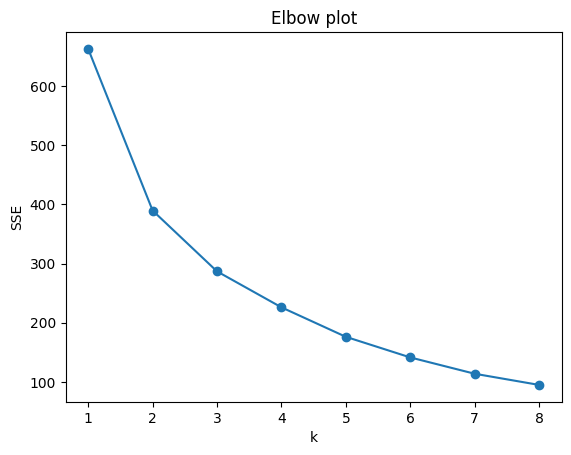

2 0.458
3 0.474
4 0.424
5 0.413
6 0.414
7 0.42
8 0.397


In [35]:
ks = range(1, 9)
sse = [KMeans(k, n_init=10, random_state=42).fit(X).inertia_ for k in ks]
plt.plot(ks, sse, "o-"); plt.xlabel("k"); plt.ylabel("SSE"); plt.title("Elbow plot"); plt.show()
for k in range(2, 9):
    labels = KMeans(k, n_init=10, random_state=42).fit_predict(X)
    print(k, round(silhouette_score(X, labels), 3))

The elbow plot has no sharp bend: SSE drops most from k = 1 to 2 and then decreases gradually. The silhouette score is highest at k = 3 (0.474), followed by k = 2 (0.458) and k = 4 (0.424). We chose k = 4 because it gives a finer split while its silhouette score is only slightly lower than at k = 3. At k = 3, a small cluster of 6 countries with a very high fatality rate (9.54%) already appears, but only 5 of the 10 countries in our high-fatality cluster (7.35%) are in it; the other 5 are merged into a large low-fatality cluster. The paper used 3 clusters, so our choice differs slightly. This is expected because the paper clustered weekly trajectories and we cluster a single snapshot.

#**Step 6: Clustering**

In [36]:
k = 4 # replace with your choice
km = KMeans(k, n_init=10, random_state=42).fit(X)
df["cluster"] = km.labels_
print(df["cluster"].value_counts().sort_index())  # sums to your Step 3 count
print(df.groupby("cluster")[feats].mean().round(2)) # original (unscaled) values
print(df[df["location"].isin(["Pakistan", "Japan"])][["location", "cluster"] + feats])

cluster
0     64
1     10
2    112
3     35
Name: count, dtype: int64
         total_cases_per_million  total_deaths_per_million  fatality_rate
cluster                                                                  
0                       78647.61                    847.46           1.22
1                        6422.06                    445.38           7.35
2                       11548.00                    161.73           1.45
3                       99044.82                   2299.26           2.62
        location  cluster  total_cases_per_million  total_deaths_per_million  \
189227     Japan        2                 10403.02                    125.05   
291574  Pakistan        2                  4595.68                    101.96   

        fatality_rate  
189227       1.202058  
291574       2.218631  


**Check: clustering with k = 3 for comparison with the chosen k = 4 (see the explanation in Step 5).**

In [37]:
km3 = KMeans(3, n_init=10, random_state=42).fit(X)
df["cluster_k3"] = km3.labels_
print(df.groupby("cluster_k3")[feats].mean().round(2))

# Ensure cluster_scaled is defined (copied from the chosen 4-cluster run)
df["cluster_scaled"] = df["cluster"]

print(pd.crosstab(df["cluster_scaled"], df["cluster_k3"]))

            total_cases_per_million  total_deaths_per_million  fatality_rate
cluster_k3                                                                  
0                          19963.80                   1655.36           9.54
1                          16923.22                    204.32           1.53
2                          92223.68                   1481.08           1.78
cluster_k3      0    1   2
cluster_scaled            
0               0   17  47
1               5    5   0
2               0  112   0
3               1    0  34


Cluster names: 0 = high cases, moderate deaths, low fatality (64 countries); 1 = low cases, high fatality (10); 2 = low cases, low deaths (112); 3 = very high cases, very high deaths (35). The sizes add up to 221.

Pakistan is in cluster 2 (4,596 cases and 102 deaths per million, fatality 2.2%). Its deaths and fatality rate are close to the cluster 2 averages (162 deaths per million, 1.45%), and it is far from cluster 1 (445 deaths per million, 7.35% fatality) and from clusters 0 and 3 (over 78,000 cases per million). Japan is in cluster 2 (10,403 cases and 125 deaths per million, fatality 1.20%), close to all three cluster 2 averages.

#**7 a) Interpretation**

Without scaling, the cluster sizes became 109, 45, 13 and 54 countries, compared with 64, 10, 112 and 35 in the scaled run. The average fatality rate was almost the same in all unscaled clusters (1.06% to 2.00%), while cases per million ranged from 7,785 to 151,144, and deaths per million rose in the same order. The unscaled clusters are therefore essentially ordered by cases per million. This happens because k-means uses Euclidean distance, and cases per million are in the thousands while fatality rate is only a few percent, so the feature with the largest values dominates and fatality rate has almost no influence. As a result, the unscaled run does not isolate the 10 countries with a 7.35% average fatality rate (scaled cluster 1); the cross-table shows that all 10 were merged with 99 other countries into one unscaled cluster of 109. After scaling, each feature has equal weight, so the clusters reflect all three features.

#**Optional:** See how countries moved between the two versions

In [38]:
# 1. Assign scaled clusters
df["cluster_scaled"] = df["cluster"]

# 2. Run k-Means on raw (unscaled) features
km_raw = KMeans(n_clusters=4, n_init=10, random_state=42).fit(df[feats])
df["cluster_raw"] = km_raw.labels_

# 3. Print the cross-tabulation
print(pd.crosstab(df["cluster_scaled"], df["cluster_raw"]))

cluster_raw      0   1  2   3
cluster_scaled               
0                0  25  6  33
1               10   0  0   0
2               99   0  0  13
3                0  20  7   8


#**7b) Continent vs cluster**

In [39]:
print(pd.crosstab(df["continent"], df["cluster"]))
ct = pd.crosstab(df["continent"], df["cluster_scaled"])
print(ct)

# Percent of each continent in each cluster (easier to read)
print((pd.crosstab(df["continent"], df["cluster_scaled"], normalize="index") * 100).round(1))

cluster         0  1   2   3
continent                   
Africa          7  4  44   1
Asia           13  4  26   2
Europe         23  0   6  22
North America  16  1  22   2
Oceania         3  0  11   0
South America   2  1   3   8
cluster_scaled   0  1   2   3
continent                    
Africa           7  4  44   1
Asia            13  4  26   2
Europe          23  0   6  22
North America   16  1  22   2
Oceania          3  0  11   0
South America    2  1   3   8
cluster_scaled     0    1     2     3
continent                            
Africa          12.5  7.1  78.6   1.8
Asia            28.9  8.9  57.8   4.4
Europe          45.1  0.0  11.8  43.1
North America   39.0  2.4  53.7   4.9
Oceania         21.4  0.0  78.6   0.0
South America   14.3  7.1  21.4  57.1


#**7c) Testing and reporting differences**
Countries that test less find fewer cases, so their cases per million look low and their fatality rate looks high, because deaths are divided by an undercount of cases. Deaths can also be undercounted, and the definition of a COVID-19 death varies. Reporting delays and revisions can shift values on a single date, and small countries have unstable per-million values. Some countries may therefore sit in a cluster because of how they count rather than how the disease behaved.

The clusters are not purely geographic. Europe is mostly in the high-case clusters 0 and 3 (88% together), while Africa (79%) and Oceania (79%) are mostly in cluster 2. Asia and North America are spread across several clusters, and every cluster contains countries from at least four continents. This partly agrees with Gohari et al. (2022), who concluded that variation reflects health policy more than geography.

In [40]:
for seed in [1, 7, 42, 99]:
    lab = KMeans(4, n_init=10, random_state=seed).fit_predict(X)
    print(seed, sorted(pd.Series(lab).value_counts().tolist()))

1 [1, 27, 72, 121]
7 [10, 31, 68, 112]
42 [10, 35, 64, 112]
99 [10, 33, 66, 112]




#**7d) Fayyad criteria**
- **Valid:**
The cluster sizes stayed about the same with different random seeds, so the result is stable.

- **Novel:** Fatality rate separates some countries from others with similar case numbers, which case counts alone would hide.
- **Useful:** Health planners can compare countries with similar outcomes and find those that may need better testing or support.
- **Understandable:**  Three features and four named clusters are easy to explain.